# CNN terrain model comparison

Train two fixed CNN variants on the 32×32 terrain images and compare them with the saved no-rainfall models. This uses cleaned training rows and cross-validation only; the held-out Imelda test data is not loaded.

## 1. Check the saved terrain tiles

The array must match the cleaned training row order. Stored tile values already represent relative elevation in meters divided by the fixed 10-meter constant; use them directly, without fitting a scale on validation data.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root.")
training = pd.read_csv(project_root / "data" / "processed" / "training_clean.csv")
tiles_path = project_root / "data" / "processed" / "tiles" / "train_tiles.npy"
index_path = project_root / "data" / "processed" / "tiles" / "train_tiles_row_index.npy"
tiles = np.load(tiles_path, mmap_mode="r")
row_index = np.load(index_path)
print("Shape:", tiles.shape, "dtype:", tiles.dtype)
print("Min:", float(tiles.min()), "max:", float(tiles.max()), "mean:", float(tiles.mean()))
print("Exactly-zero pixel share:", float(np.count_nonzero(tiles == 0) / tiles.size))
matches_order = tiles.shape == (len(training), 32, 32) and np.array_equal(
    row_index, np.arange(len(training), dtype=row_index.dtype)
)
print("Row index matches cleaned training order:", matches_order)
if not matches_order:
    raise ValueError("Terrain tiles do not match the cleaned training row order.")
print("Fixed scaling: use saved relative-elevation values (meters / 10); no validation scaling is fitted.")

Shape: (66514, 32, 32) dtype: float16


Min: -4.3671875 max: 3.34375 mean: -0.005794525146484375


Exactly-zero pixel share: 0.014850609458159185
Row index matches cleaned training order: True
Fixed scaling: use saved relative-elevation values (meters / 10); no validation scaling is fitted.


**My observations:** The 66,514 terrain tiles are in the same order as the cleaned training data. Their stored values already use relative elevation divided by 10, so no additional validation-based scaling was needed. About 1.49% of pixels are exactly zero; zero values can include valid relative elevations as well as filled missing pixels.

## 2. Run the CNN cross-validation

Each model uses five geographic area folds and three leave-one-storm-out folds. The hybrid preprocessing is fit on training rows inside each fold and excludes rainfall. Fixed training settings are seed 42, Adam at 0.001, batch size 256, and 20 epochs. This can take about an hour on CPU.

In [2]:
from src.cnn import cross_validate_cnn
from src.features import area_group_splits, leave_one_storm_out_splits

area_splits = list(area_group_splits(training, n_splits=5))
storm_splits = list(leave_one_storm_out_splits(training))
split_sets = {
    "area_group": area_splits,
    "leave_one_storm_out": storm_splits,
}
cnn_runs = {}
cnn_times = {}
for model_name, drop_features in (
    ("cnn_tile_only", ()),
    ("cnn_hybrid", ("rainfall_inches",)),
):
    cnn_runs[model_name] = {}
    started_model = time.perf_counter()
    for split_name, splits in split_sets.items():
        started_split = time.perf_counter()
        summary, oof, diagnostics = cross_validate_cnn(
            model_name,
            training,
            tiles,
            splits,
            split_name,
            drop_features=drop_features,
        )
        cnn_runs[model_name][split_name] = {
            "summary": summary,
            "oof": oof,
            "diagnostics": diagnostics,
        }
        print(
            f"{model_name} {split_name}: {time.perf_counter() - started_split:.1f} seconds"
        )
    cnn_times[model_name] = time.perf_counter() - started_model
    print(f"{model_name} total: {cnn_times[model_name]:.1f} seconds")
print("All CNN results and OOF predictions were saved with save_results.")

Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_cnn_tile_only_area_group.csv
cnn_tile_only area_group: 1909.7 seconds


Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_cnn_tile_only_leave_one_storm_out.csv
cnn_tile_only leave_one_storm_out: 567.4 seconds
cnn_tile_only total: 2477.2 seconds


Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_cnn_hybrid_area_group.csv
cnn_hybrid area_group: 1494.9 seconds


Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_cnn_hybrid_leave_one_storm_out.csv
cnn_hybrid leave_one_storm_out: 560.7 seconds
cnn_hybrid total: 2055.6 seconds
All CNN results and OOF predictions were saved with save_results.


**My observations:** Both CNN variants completed all five area folds and three held-out-storm folds, and their summary metrics and out-of-fold predictions were saved. The full validation run took about 75.5 minutes.

## 3. Compare overall model scores

Show the saved mean cross-validation scores for the three no-rainfall table models and both CNNs on both validation designs.

In [3]:
from src.evaluate import RESULTS_PATH

comparison_models = (
    "logistic_regression_no_rain",
    "lightgbm_no_rain",
    "mlp_no_rain",
    "cnn_tile_only",
    "cnn_hybrid",
)
results = pd.read_csv(RESULTS_PATH)
comparison = results.loc[
    results["model"].isin(comparison_models)
    & results["split"].isin(("area_group", "leave_one_storm_out"))
    & results["fold"].eq("mean"),
    ["model", "split", "recall", "precision", "f1", "roc_auc", "pr_auc"],
].sort_values(["split", "model"]).reset_index(drop=True)
if len(comparison) != len(comparison_models) * 2:
    raise ValueError("Expected mean results for all five models on both splits.")
display(comparison)

,model,split,recall,precision,f1,roc_auc,pr_auc
0,cnn_hybrid,area_group,0.831800,0.786873,0.808642,0.879720,0.864083
1,cnn_tile_only,area_group,0.726125,0.705740,0.715376,0.773771,0.756227
2,lightgbm_no_rain,area_group,0.852761,0.801182,0.826129,0.891287,0.867742
3,logistic_regression_no_rain,area_group,0.790242,0.701920,0.743392,0.780928,0.743125
4,mlp_no_rain,area_group,0.829115,0.751848,0.788396,0.853027,0.831565
5,cnn_hybrid,leave_one_storm_out,0.849153,0.778106,0.811765,0.879087,0.863374
6,cnn_tile_only,leave_one_storm_out,0.816290,0.666985,0.733741,0.769188,0.751416
7,lightgbm_no_rain,leave_one_storm_out,0.884294,0.805087,0.842806,0.901477,0.877192
8,logistic_regression_no_rain,leave_one_storm_out,0.792082,0.701789,0.744159,0.781411,0.743857
9,mlp_no_rain,leave_one_storm_out,0.824849,0.756469,0.789126,0.854097,0.831796


**My observations:** LightGBM without rainfall scored highest on both splits. The hybrid CNN was closer to it than the tile-only CNN, but its recall and ROC-AUC were still lower: 0.8318 and 0.8797 on area folds, and 0.8492 and 0.8791 on storm folds.

## 4. Check performance for each held-out storm

Use the leave-one-storm-out OOF probabilities and the default 0.5 cutoff. OOF row indices map predictions back to the cleaned data's storm names.

In [4]:
from src.evaluate import compute_metrics

storm_rows = []
for model_name in comparison_models:
    if model_name in cnn_runs:
        oof = cnn_runs[model_name]["leave_one_storm_out"]["oof"].copy()
    else:
        oof_path = project_root / "reports" / (
            f"oof_{model_name}_leave_one_storm_out.csv"
        )
        oof = pd.read_csv(oof_path)
    oof["storm_name"] = training["storm_name"].to_numpy()[
        oof["row_index"].astype(int).to_numpy()
    ]
    for storm_name, group in oof.groupby("storm_name", sort=True):
        metrics = compute_metrics(group["y_true"], group["y_prob"], threshold=0.5)
        storm_rows.append({
            "model": model_name,
            "storm": storm_name,
            "recall": metrics["recall"],
            "roc_auc": metrics["roc_auc"],
        })
storm_table = pd.DataFrame(storm_rows).sort_values(["storm", "model"])
display(storm_table.reset_index(drop=True))

,model,storm,recall,roc_auc
0,cnn_hybrid,Hurricane Harvey,0.834615,0.875815
1,cnn_tile_only,Hurricane Harvey,0.833939,0.770125
2,lightgbm_no_rain,Hurricane Harvey,0.878983,0.899057
3,logistic_regression_no_rain,Hurricane Harvey,0.789572,0.781208
4,mlp_no_rain,Hurricane Harvey,0.823291,0.850761
5,cnn_hybrid,Memorial Day Flood,0.878251,0.882555
6,cnn_tile_only,Memorial Day Flood,0.837152,0.775418
7,lightgbm_no_rain,Memorial Day Flood,0.895617,0.906751
8,logistic_regression_no_rain,Memorial Day Flood,0.802782,0.785667
9,mlp_no_rain,Memorial Day Flood,0.837880,0.860309


**My observations:** LightGBM without rainfall had the highest recall and ROC-AUC for each held-out storm. The hybrid CNN had better ROC-AUC than the tile-only CNN for every storm, while tile-only ROC-AUC remained around 0.76–0.78.

## 5. Check area-selected cutoffs on the held-out storms

For each CNN, choose the highest cutoff that reaches recall 0.85 on its area-group OOF predictions. Apply that unchanged cutoff to overall storm OOF predictions and each storm separately.

In [5]:
from src.threshold import pick_threshold

threshold_rows = []
chosen_thresholds = {}
for model_name in ("cnn_tile_only", "cnn_hybrid"):
    area_oof = cnn_runs[model_name]["area_group"]["oof"]
    storm_oof = cnn_runs[model_name]["leave_one_storm_out"]["oof"].copy()
    threshold = pick_threshold(area_oof, target_recall=0.85)
    chosen_thresholds[model_name] = threshold
    if threshold is None:
        threshold_rows.append({"model": model_name, "scope": "area cutoff", "threshold": None,
                               "recall": None, "precision": None})
        continue
    storm_oof["storm_name"] = training["storm_name"].to_numpy()[
        storm_oof["row_index"].astype(int).to_numpy()
    ]
    scopes = [("overall", storm_oof), *list(storm_oof.groupby("storm_name", sort=True))]
    for scope, group in scopes:
        metrics = compute_metrics(group["y_true"], group["y_prob"], threshold=threshold)
        threshold_rows.append({
            "model": model_name,
            "scope": scope,
            "threshold": threshold,
            "recall": metrics["recall"],
            "precision": metrics["precision"],
        })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)

,model,scope,threshold,recall,precision
0,cnn_tile_only,overall,0.38,0.906906,0.618552
1,cnn_tile_only,Hurricane Harvey,0.38,0.915237,0.617305
2,cnn_tile_only,Memorial Day Flood,0.38,0.924259,0.609778
3,cnn_tile_only,Tax Day Flood,0.38,0.880888,0.629351
4,cnn_hybrid,overall,0.47,0.868267,0.766443
5,cnn_hybrid,Hurricane Harvey,0.47,0.855658,0.775327
6,cnn_hybrid,Memorial Day Flood,0.47,0.894890,0.749239
7,cnn_hybrid,Tax Day Flood,0.47,0.855358,0.775405


**My observations:** Both area-selected cutoffs kept recall above 0.85 for all three storms. Tile-only used 0.38 and had storm recalls from 0.8809 to 0.9243; hybrid used 0.47 and had recalls from 0.8554 to 0.8949.

## 6. Plot training loss for the first area fold

Each curve records mean training loss per epoch for the first area-group fold. It shows optimization progress, not validation performance.

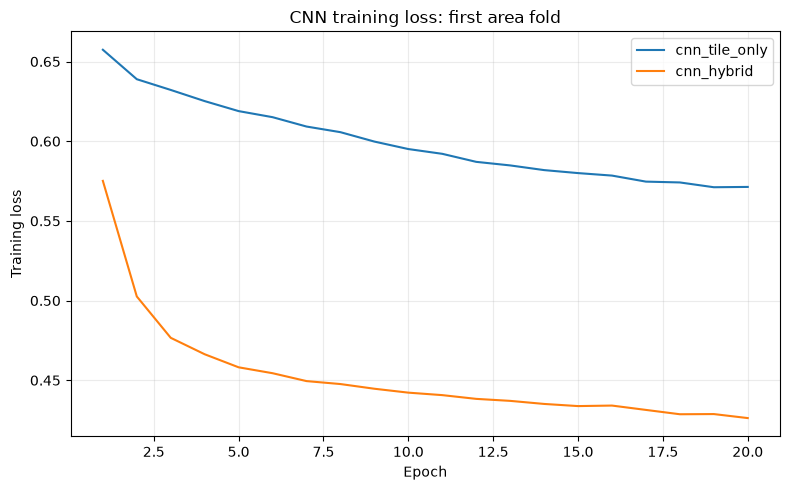

Saved: C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\cnn_training_loss.png


In [6]:
figure, axis = plt.subplots(figsize=(8, 5))
for model_name in ("cnn_tile_only", "cnn_hybrid"):
    losses = cnn_runs[model_name]["area_group"]["diagnostics"]["fold_losses"][1]
    axis.plot(np.arange(1, len(losses) + 1), losses, label=model_name)
axis.set(xlabel="Epoch", ylabel="Training loss", title="CNN training loss: first area fold")
axis.grid(alpha=0.25)
axis.legend()
figure.tight_layout()
loss_figure_path = project_root / "reports" / "figures" / "cnn_training_loss.png"
figure.savefig(loss_figure_path, dpi=150, bbox_inches="tight")
display(figure)
plt.close(figure)
print("Saved:", loss_figure_path)

**My observations:** Training loss declined across the 20 epochs for both models. The hybrid curve was lower in this fold, but training loss alone does not show which model generalizes better; use the validation scores for that comparison.

## 7. Summarize training time

Report the measured time for each model and split from this notebook run.

In [7]:
time_rows = []
for model_name in ("cnn_tile_only", "cnn_hybrid"):
    for split_name in split_sets:
        seconds = sum(cnn_runs[model_name][split_name]["diagnostics"]["fold_seconds"].values())
        time_rows.append({"model": model_name, "split": split_name, "seconds": seconds,
                          "minutes": seconds / 60})
time_table = pd.DataFrame(time_rows)
display(time_table)
print("Combined CNN validation time (minutes):", time_table["minutes"].sum())

,model,split,seconds,minutes
0,cnn_tile_only,area_group,1909.332080,31.822201
1,cnn_tile_only,leave_one_storm_out,567.111934,9.451866
2,cnn_hybrid,area_group,1494.253124,24.904219
3,cnn_hybrid,leave_one_storm_out,560.276463,9.337941


Combined CNN validation time (minutes): 75.51622666666759


**My observations:** The CNN validation run took 75.52 minutes total. Area folds took longer than storm folds for both models; the hybrid run was faster than tile-only overall.

## Limitation

A 320 m terrain tile around a point near a 1 km grid-cell border can overlap the neighboring cell. Therefore, area folds are slightly less strict for the CNN than for the table-feature models.